# №10. Морфологические операции

Реализуем алгоритм van Herk — Gil — Werman для минимума и максимума в скользящем окне.
Перенесём его на прямоугольное окно изображения и сравним очистку шума «соль/перец»
двумя морфологическими цепочками и медианным фильтром.

Все вычисления выполняются в NumPy. Окна центрированы, их размеры — положительные
нечётные числа. На границах продолжаем крайний пиксель (`edge`).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    if figsize is None:
        figsize = (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. Одномерный алгоритм van Herk — Gil — Werman

После продолжения границ разбиваем массив $a$ на блоки длины $k$.
В каждом блоке считаем два массива:

- $P_i$ — экстремум от начала блока до позиции $i$;
- $S_i$ — экстремум от позиции $i$ до конца блока.

Для окна с началом $j$ и концом $j+k-1$ получаем:

$$R_j=\operatorname{ext}(S_j, P_{j+k-1}),\qquad
\operatorname{ext}\in\{\min,\max\}.$$

Окно длины $k$ пересекает максимум два блока. Каждый элемент участвует в одном
прямом и одном обратном накоплении. Поэтому вычисление экстремумов и их объединение
занимают $O(n)$ операций.

При $k\geq 2n-1$ каждое центрированное окно охватывает весь исходный массив.
В этом случае сразу используем общий экстремум. Для остальных размеров длина
массива с продолженными границами меньше $3n$.

In [3]:
def block_extrema(values, size, mode="min"):
    """Префиксы и суффиксы экстремумов внутри блоков длины size."""
    operation = np.minimum if mode == "min" else np.maximum
    prefix = np.empty_like(values)
    suffix = np.empty_like(values)
    for start in range(0, values.size, size):
        stop = min(start + size, values.size)
        block = values[start:stop]
        prefix[start:stop] = operation.accumulate(block)
        suffix[start:stop] = operation.accumulate(block[::-1])[::-1]
    return prefix, suffix


def vhgw_1d(values, size=3, mode="min"):
    """Минимум или максимум в центрированном окне за O(n)."""
    values = np.asarray(values)
    operation = np.minimum if mode == "min" else np.maximum
    if size >= 2 * values.size - 1:
        return np.full_like(values, operation.reduce(values))

    radius = size // 2
    padded = np.pad(values, radius, mode="edge")
    prefix, suffix = block_extrema(padded, size, mode)
    start = np.arange(values.size)
    end = start + size - 1
    return operation(suffix[start], prefix[end])

Продолженный массив: [ 3  3  3  7  2  4  9  2  1 10  3  8 11 11 11]
Префиксы максимумов:  [ 3  3  3  7  7  4  9  9  9 10  3  8 11 11 11]
Суффиксы максимумов:  [ 7  7  7  7  2 10 10 10 10 10 11 11 11 11 11]
Минимум в окне 5:     [2 2 2 2 1 1 1 1 1 3 3]
Максимум в окне 5:    [ 7  7  9  9  9 10 10 10 11 11 11]


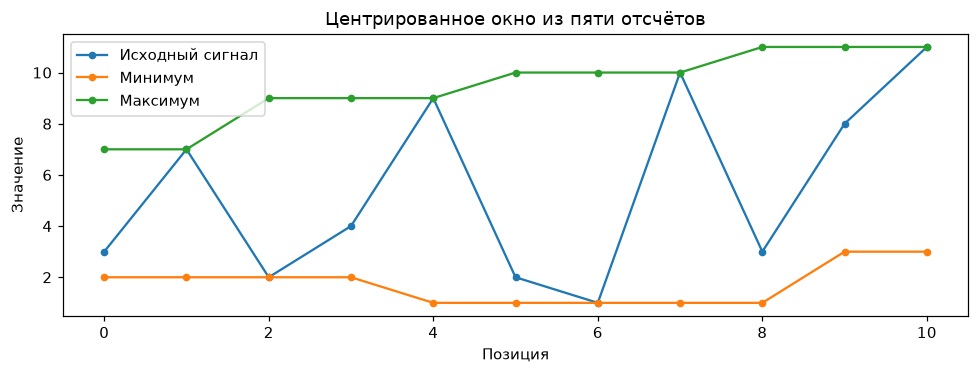

In [4]:
signal = np.array([3, 7, 2, 4, 9, 2, 1, 10, 3, 8, 11], dtype=np.int16)
window = 5
padded = np.pad(signal, window // 2, mode="edge")
prefix, suffix = block_extrema(padded, window, "max")
print("Продолженный массив:", padded)
print("Префиксы максимумов: ", prefix)
print("Суффиксы максимумов: ", suffix)
print("Минимум в окне 5:    ", vhgw_1d(signal, window, "min"))
print("Максимум в окне 5:   ", vhgw_1d(signal, window, "max"))

fig, ax = plt.subplots(figsize=(9, 3.5))
for values, label in [(signal, "Исходный сигнал"),
                      (vhgw_1d(signal, window, "min"), "Минимум"),
                      (vhgw_1d(signal, window, "max"), "Максимум")]:
    ax.plot(values, marker="o", markersize=4, label=label)
ax.set(xlabel="Позиция", ylabel="Значение", title="Центрированное окно из пяти отсчётов")
ax.legend()
fig.tight_layout()
plt.show()

## 2. Двумерный вариант через транспонирование

Для прямоугольного окна $h\times w$ экстремум можно вычислить последовательно:
сначала вдоль строк по $w$ пикселям, затем вдоль столбцов по $h$ пикселям.
Транспонирование превращает столбцы в строки. В конце возвращаем исходный порядок осей.

$$\min_{i,j} I[y+i,x+j]=\min_i\left(\min_j I[y+i,x+j]\right).$$

Для максимума действует такая же формула. При размере изображения $H\times W$
общее число операций равно $O(HW)$.

Размер изображения: (300, 451)


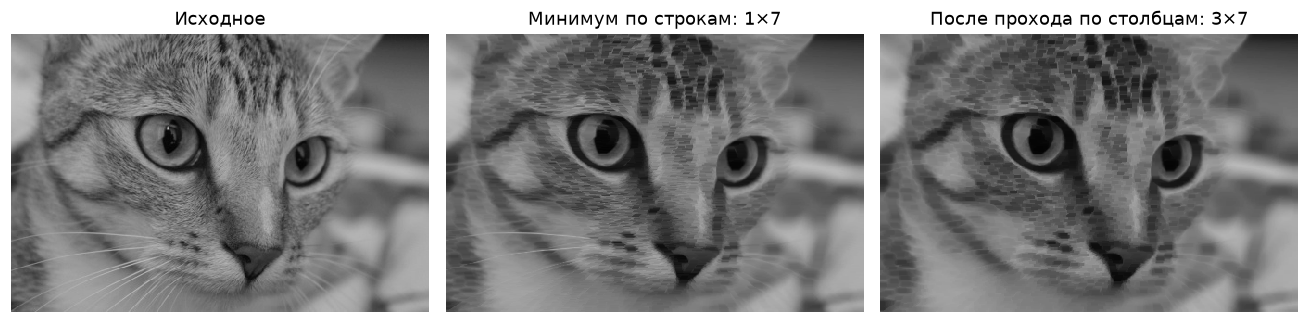

In [5]:
def vhgw_2d(image, window=(3, 3), mode="min"):
    """Прямоугольный фильтр: строки, транспонирование, строки, возврат осей."""
    image = np.asarray(image)
    height, width = window
    rows = np.stack([vhgw_1d(row, width, mode) for row in image])
    transposed = rows.T
    columns = np.stack([vhgw_1d(row, height, mode) for row in transposed])
    return columns.T


rgb = np.array(Image.open("data/scene.jpg").convert("RGB"))
gray = to_uint8(rgb.astype(float) @ np.array([0.2126, 0.7152, 0.0722]))
rows_min = np.stack([vhgw_1d(row, 7, "min") for row in gray])
rectangle_min = np.stack([vhgw_1d(row, 3, "min") for row in rows_min.T]).T
print("Размер изображения:", gray.shape)
show_images([gray, rows_min, rectangle_min],
            ["Исходное", "Минимум по строкам: 1×7", "После прохода по столбцам: 3×7"])

## 3. Эрозия, дилатация, открытие и закрытие

Используем плоское прямоугольное структурирующее окно $B$:

$$\varepsilon_B(I)=\min_B I,\qquad \delta_B(I)=\max_B I,$$
$$I\circ B=\delta_B(\varepsilon_B(I)),\qquad
I\bullet B=\varepsilon_B(\delta_B(I)).$$

Эрозия расширяет тёмные области. Дилатация расширяет светлые.
Открытие удаляет мелкие светлые элементы; закрытие заполняет мелкие тёмные промежутки.

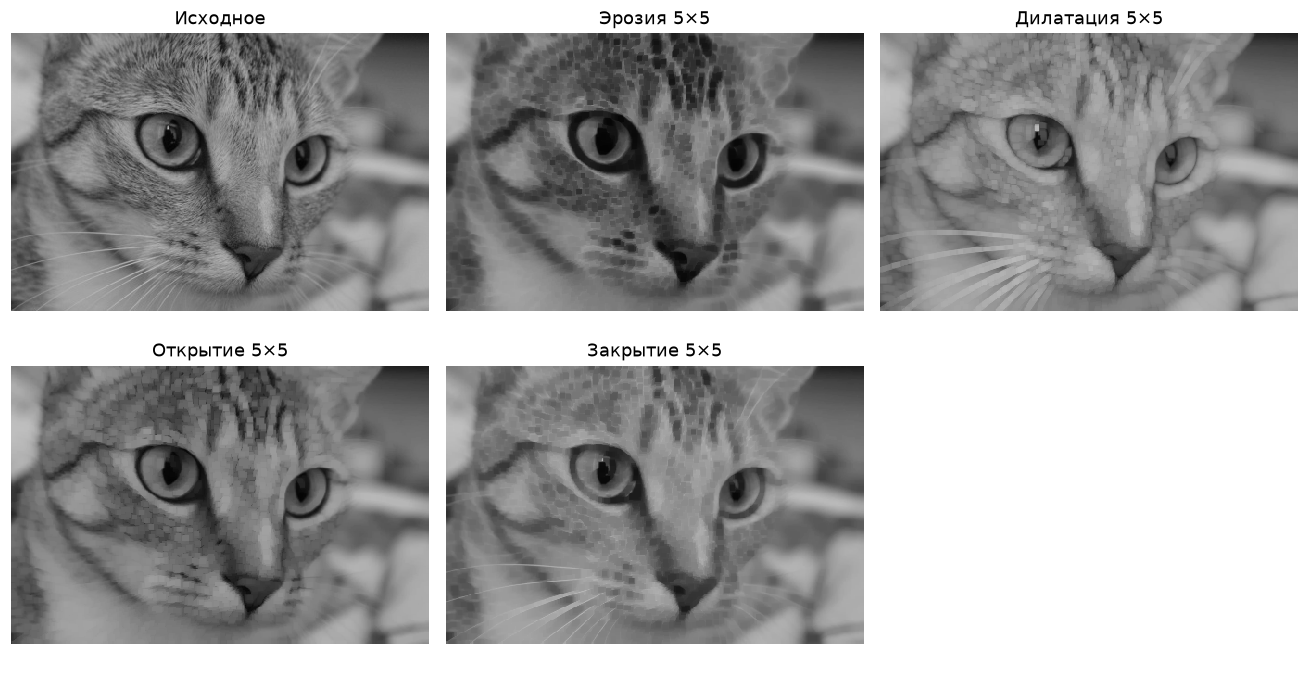

In [6]:
def erosion(image, window=(3, 3)):
    return vhgw_2d(image, window, "min")


def dilation(image, window=(3, 3)):
    return vhgw_2d(image, window, "max")


def opening(image, window=(3, 3)):
    return dilation(erosion(image, window), window)


def closing(image, window=(3, 3)):
    return erosion(dilation(image, window), window)


window = (5, 5)
show_images([gray, erosion(gray, window), dilation(gray, window),
             opening(gray, window), closing(gray, window)],
            ["Исходное", "Эрозия 5×5", "Дилатация 5×5", "Открытие 5×5", "Закрытие 5×5"], cols=3)

## 4. Шум «соль/перец» и сравнение фильтров

Выбираем 8% различных координат с `seed=42` и заменяем их яркости на 0 или 255
с равными вероятностями. Все методы получают один шумовой массив.

Сравниваем три метода с одинаковым окном:

1. открытие → закрытие;
2. закрытие → открытие;
3. медианный фильтр.

Медиану считаем напрямую в скользящем окне. Для оценки используем чистую фотографию:

$$\mathrm{MAE}=\frac{1}{N}\sum|I_{\mathrm{out}}-I|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{N}\sum(I_{\mathrm{out}}-I)^2}.$$

Для всех методов действует одно правило продолжения границ — `edge`.

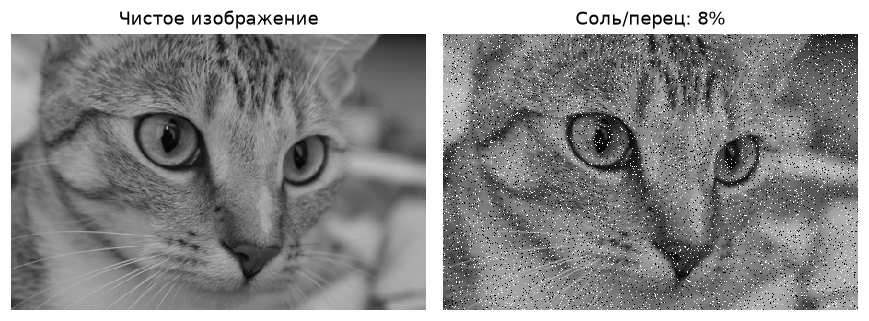

Изменённая доля пикселей: 8.00%


In [7]:
def salt_pepper(image, fraction=0.08, seed=42):
    result = np.asarray(image).copy()
    rng = np.random.default_rng(seed)
    count = round(fraction * result.size)
    coordinates = rng.choice(result.size, size=count, replace=False)
    result.flat[coordinates] = rng.choice([0, 255], size=count)
    return result


def median_filter(image, window=(3, 3)):
    image = np.asarray(image)
    height, width = window
    padded = np.pad(image, ((height // 2, height // 2), (width // 2, width // 2)), mode="edge")
    windows = np.lib.stride_tricks.sliding_window_view(padded, (height, width))
    return np.median(windows, axis=(-2, -1))


def errors(result, reference):
    difference = np.asarray(result, dtype=float) - np.asarray(reference, dtype=float)
    return np.mean(np.abs(difference)), np.sqrt(np.mean(difference**2))


noisy = salt_pepper(gray)
show_images([gray, noisy], ["Чистое изображение", "Соль/перец: 8%"], cols=2)
print("Изменённая доля пикселей:", f"{np.mean(noisy != gray):.2%}")

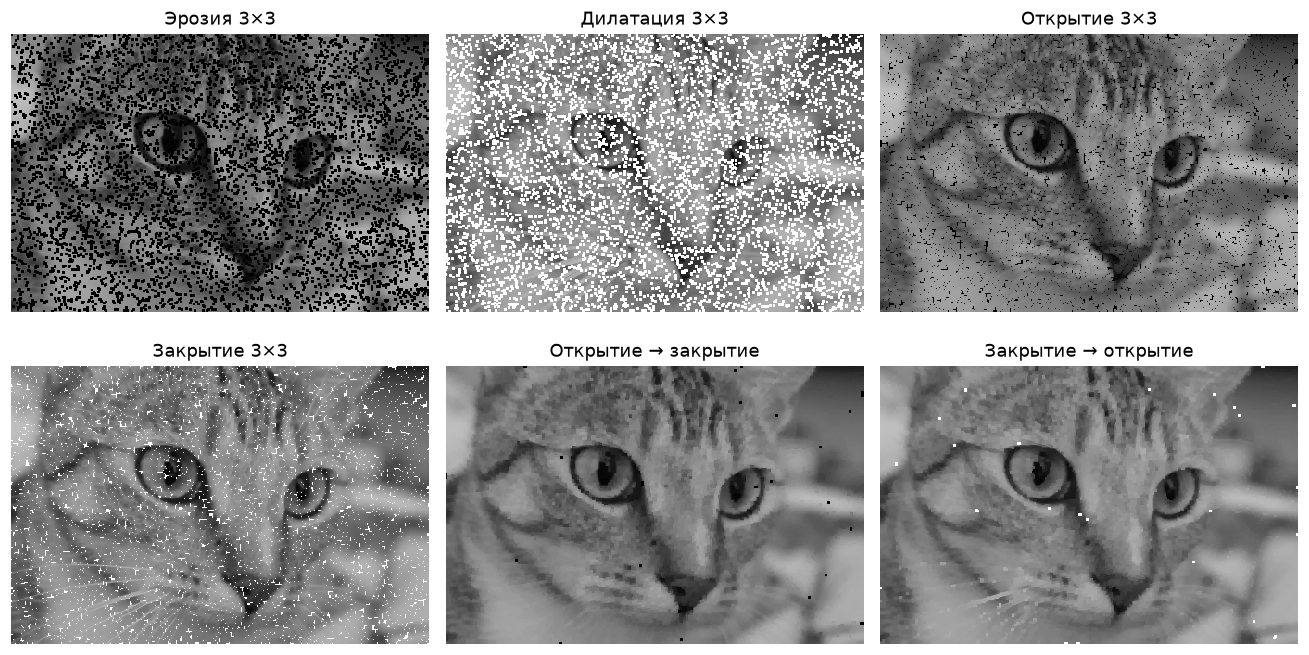

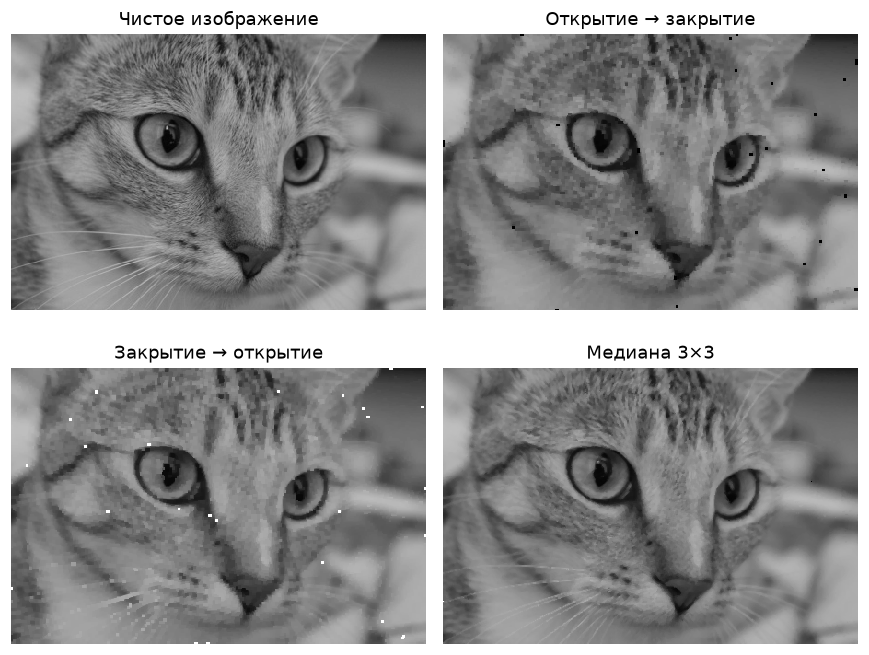

In [8]:
window = (3, 3)
opened = opening(noisy, window)
closed = closing(noisy, window)
open_close = closing(opened, window)
close_open = opening(closed, window)
median = median_filter(noisy, window)

show_images([erosion(noisy, window), dilation(noisy, window), opened, closed,
             open_close, close_open],
            ["Эрозия 3×3", "Дилатация 3×3", "Открытие 3×3", "Закрытие 3×3",
             "Открытие → закрытие", "Закрытие → открытие"], cols=3)
show_images([gray, open_close, close_open, median],
            ["Чистое изображение", "Открытие → закрытие", "Закрытие → открытие", "Медиана 3×3"], cols=2)

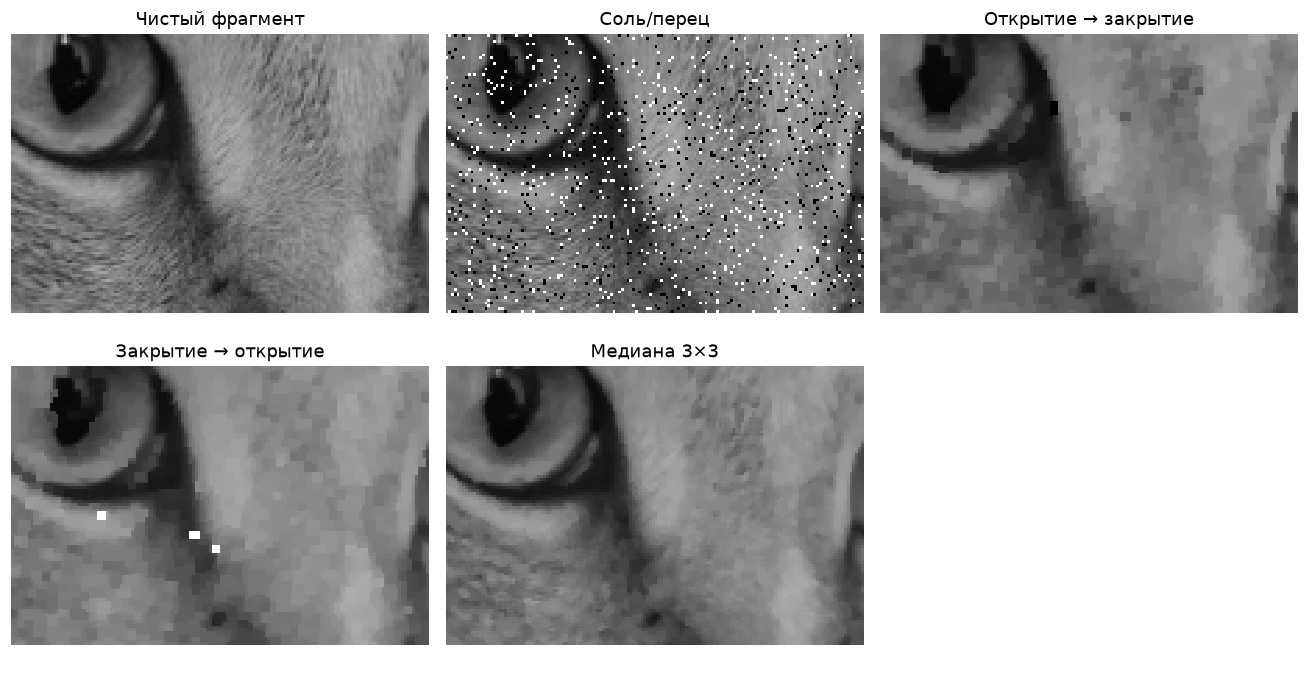

Метод                           MAE     RMSE
С шумом                      10.212   37.338
Открытие → закрытие           4.793   10.126
Закрытие → открытие           4.836   10.838
Медиана                       2.694    5.330
Минимальная MAE в этом опыте: Медиана
Минимальная RMSE в этом опыте: Медиана


In [9]:
# Фрагмент вокруг глаза и усов показывает тонкие светлые и тёмные детали.
h, w = gray.shape
crop = np.s_[h // 3:2 * h // 3, w // 3:2 * w // 3]
show_images([gray[crop], noisy[crop], open_close[crop], close_open[crop], median[crop]],
            ["Чистый фрагмент", "Соль/перец", "Открытие → закрытие",
             "Закрытие → открытие", "Медиана 3×3"], cols=3)

methods = {"С шумом": noisy, "Открытие → закрытие": open_close,
           "Закрытие → открытие": close_open, "Медиана": median}
print(f"{'Метод':26s} {'MAE':>8s} {'RMSE':>8s}")
for name, result in methods.items():
    mae, rmse = errors(result, gray)
    print(f"{name:26s} {mae:8.3f} {rmse:8.3f}")

filtered = {name: result for name, result in methods.items() if name != "С шумом"}
best_mae = min(filtered, key=lambda name: errors(filtered[name], gray)[0])
best_rmse = min(filtered, key=lambda name: errors(filtered[name], gray)[1])
print("Минимальная MAE в этом опыте:", best_mae)
print("Минимальная RMSE в этом опыте:", best_rmse)

### Изменение размера окна

Повторяем сравнение для окна 5×5 на том же шумовом массиве.
Более крупное окно охватывает больше выбросов и сильнее меняет мелкую фактуру.

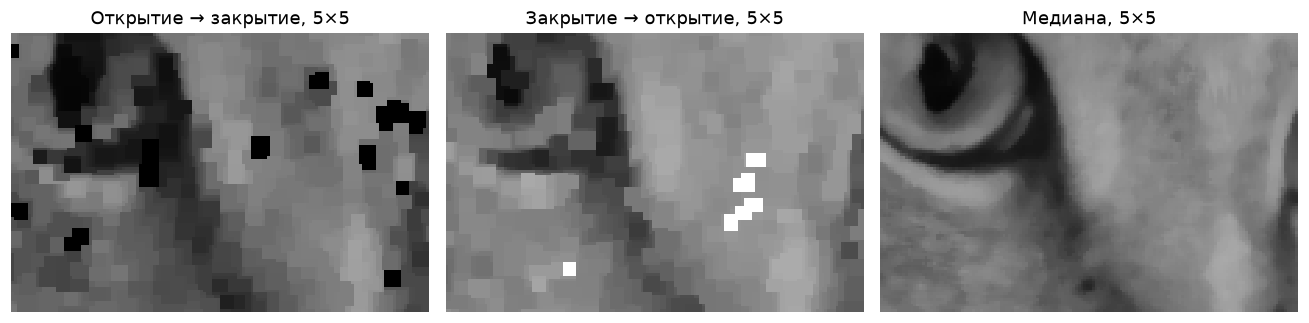

Метод, окно 5×5                 MAE     RMSE
Открытие → закрытие          13.306   26.903
Закрытие → открытие          12.320   24.989
Медиана                       4.152    7.314


In [10]:
window5 = (5, 5)
results5 = [closing(opening(noisy, window5), window5),
            opening(closing(noisy, window5), window5),
            median_filter(noisy, window5)]
names5 = ["Открытие → закрытие", "Закрытие → открытие", "Медиана"]
show_images([result[crop] for result in results5],
            [name + ", 5×5" for name in names5])
print(f"{'Метод, окно 5×5':26s} {'MAE':>8s} {'RMSE':>8s}")
for name, result in zip(names5, results5):
    mae, rmse = errors(result, gray)
    print(f"{name:26s} {mae:8.3f} {rmse:8.3f}")

## Вывод

Префиксы и суффиксы блоков дают оконные минимум и максимум за линейное время.
Два одномерных прохода реализуют прямоугольный двумерный фильтр и сохраняют тип пикселей.

Открытие подавляет светлые выбросы, закрытие — тёмные. Порядок операций влияет на итог:
первая операция задаёт характер изменения тонких деталей. В опыте с фотографией,
8% шума «соль/перец» и окном 3×3 медиана даёт наименьшие MAE и RMSE среди трёх методов.
Эта оценка относится к выбранному изображению, уровню шума и размеру окна.

Материал: лекция «07. Морфологические преобразования изображений», заключительный
слайд с префиксами и суффиксами алгоритма van Herk — Gil — Werman.